# Лекция 9: Компьютерное зрение
## Generative modeling: Autoregressive models & Diffusion. Часть 2

**Преподаватель:** Шевченко Елена

**Аудитория:** ФКН ВШЭ, МФТИ

---

## Содержание

1. ~~Метрики~~
   1. ~~Почему оценивать генерацию трудно~~
   2. ~~FID~~
   3. ~~Precision & Recall~~
   4. ~~Text-to-image: CLIPScore, VQAScore~~
   5. ~~VLM-as-a-judge~~
   6. ~~Люди и арены~~
2. ~~Autoregressive~~
   1. ~~Постановка задачи~~
   2. ~~PixelCNN — идея~~
   3. ~~От пикселей к токенам~~
   4. ~~VAR~~
   5. ~~Switti~~
   6. ~~Infinity~~
   7. ~~Современные AR-модели (2024–2026)~~
3. Diffusion
   1. Зачем ещё один класс генеративных моделей
   2. Forward process: зашумление
   3. Reverse process и что мы учим
   4. Сэмплирование: от DDPM к DDIM
   5. Параметризации: что именно предсказывает сеть
   6. Архитектура: как устроена $\epsilon_\theta(x_t, t)$
   7. Условная генерация: classifier guidance → CFG
   8. Latent Diffusion и cross-attention с текстом
   9. Stable Diffusion: 1.x → 2 → SDXL
   10. Итоги и мостик к лекции 10

---

## 1. Зачем ещё один класс генеративных моделей

| Модель | Обучение | Likelihood | Качество | Разнообразие | Скорость сэмплинга |
|---|---|---|---|---|---|
| GAN | adversarial | нет | высокое | mode collapse | 1 шаг |
| VAE | ELBO | нижняя оценка | размыто | хорошее | 1 шаг |
| AR | MLE | точный | высокое | хорошее | много последовательных шагов |
| Diffusion | ELBO / denoising | нижняя оценка | высокое | хорошее | много шагов |

**Идея диффузии**

- Вместо одного прыжка «шум → картинка» — много маленьких шагов расшумления
- Каждый шаг — простая задача: убрать чуть-чуть гауссова шума
- Связь с VAR из части 1: тоже итеративное уточнение от грубого к точному, но непрерывное, без дискретного токенизатора и без порядка по позициям

<img src="./assets/diffusion-model-scheme.png" alt="diffusion-model-scheme" width="1024">

Дальше разберём два процесса: forward (зашумление) и reverse (расшумление).

> Математика раздела следует [блогпосту Lilian Weng](https://lilianweng.github.io/posts/2021-07-11-diffusion-models/)

## 2. Forward process: зашумление

У нас имеется пример из реального распределения: $\mathbf{x}_0 \sim q(\mathbf{x})$

Определим *forward process* в котором мы будем добавлять небольшие порции гауссового шума в сэмпл на протяжении $T$ шагов. Получим набор зашумленных сэмплов:

$$x_1,\dots,x_T$$

Размеры шага контролируются *variance schedule*: $\{\beta_t \in (0, 1)\}_{t=1}^T$

$$q(\mathbf{x}_t \vert \mathbf{x}_{t-1}) = \mathcal{N}(\mathbf{x}_t; \sqrt{1 - \beta_t} \mathbf{x}_{t-1}, \beta_t\mathbf{I}) \quad
q(\mathbf{x}_{1:T} \vert \mathbf{x}_0) = \prod^T_{t=1} q(\mathbf{x}_t \vert \mathbf{x}_{t-1})$$

**Марковость.** Каждый шаг зависит только от предыдущего: $x_t$ получается из $x_{t-1}$, а не из всей истории. Поэтому совместное распределение раскладывается в произведение одношаговых переходов, обратный процесс тоже строится как цепочка $p_\theta(x_{t-1}\mid x_t)$, и сеть на каждом шаге видит только $x_t$ и $t$.

> Такой вариант называется VP (Variance Preserving). Есть еще VE (Variance Exploding) вариант. 

При $T \to \infty, x_T$ становится эквивалентно изотропному гауссову распределению (isotropic Gaussian distribution)

Однако на обучении нам нужен $x_t$ для случайного $t$ **за один шаг**, а не за $t$ итераций. Раскроем рекурсию (reparameterization trick):

Пусть $\alpha_t = 1 - \beta_t, \bar{\alpha}_t = \prod_{i=1}^t \alpha_i$

$$\begin{aligned}
\mathbf{x}_t 
&= \sqrt{\alpha_t}\mathbf{x}_{t-1} + \sqrt{1 - \alpha_t}\boldsymbol{\epsilon}_{t-1} & \text{ ;where } \boldsymbol{\epsilon}_{t-1}, \boldsymbol{\epsilon}_{t-2}, \dots \sim \mathcal{N}(\mathbf{0}, \mathbf{I}) \\
&= \sqrt{\alpha_t \alpha_{t-1}} \mathbf{x}_{t-2} + \sqrt{1 - \alpha_t \alpha_{t-1}} \bar{\boldsymbol{\epsilon}}_{t-2} & \text{ ;where } \bar{\boldsymbol{\epsilon}}_{t-2} \text{ merges two Gaussians (*).} \\
&= \dots \\
&= \sqrt{\bar{\alpha}_t}\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t}\boldsymbol{\epsilon} \\
q(\mathbf{x}_t \vert \mathbf{x}_0) &= \mathcal{N}(\mathbf{x}_t; \sqrt{\bar{\alpha}_t} \mathbf{x}_0, (1 - \bar{\alpha}_t)\mathbf{I})
\end{aligned}$$

(*) сумма двух независимых гауссиан — гауссиана с суммой дисперсий: $\alpha_t(1-\alpha_{t-1}) + (1-\alpha_t) = 1 - \alpha_t\alpha_{t-1}$.

**Почему variance preserving**

- Если $\mathrm{Var}(x_0)=1$, то $\mathrm{Var}(x_t)=\bar\alpha_t\cdot 1+(1-\bar\alpha_t)=1$
- На практике $T = 1000$ хватает: для линейного schedule $\bar\alpha_{1000} \approx 4\cdot 10^{-5}$, то есть коэффициент при $x_0$ в формуле выше $\sqrt{\bar\alpha_T} \approx 0.007$ — от сигнала не остаётся ничего
- Дисперсия не растёт: сигнал плавно заменяется шумом

**Schedule**

- DDPM: линейный $\beta_t$ от $10^{-4}$ до $0.02$, $T=1000$
- Stable Diffusion: «scaled linear» (линейно по $\sqrt{\beta}$) от 0.00085 до 0.012
- Cosine schedule ([Nichol & Dhariwal, 2021](https://arxiv.org/abs/2102.09672)): $\bar\alpha_t = f(t)/f(0)$, $f(t)=\cos^2\!\big(\tfrac{t/T+s}{1+s}\cdot\tfrac{\pi}{2}\big)$, $s=0.008$
  - медленнее уничтожает сигнал в начале и в конце процесса

In [2]:
# Служебные функции 
import time
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

def load_image(path: str, size: int = 128) -> torch.Tensor:
    img = Image.open(path).convert("RGB").resize((size, size))
    x = torch.from_numpy(np.array(img)).float().permute(2, 0, 1) / 127.5 - 1  # [-1, 1]
    return x.unsqueeze(0)

def to_img(x: torch.Tensor) -> np.ndarray:
    return ((x.clamp(-1, 1) + 1) / 2).permute(1, 2, 0).cpu().numpy()

def show_grid(x: torch.Tensor, titles=None, figsize=None):
    n = x.shape[0]
    fig, axs = plt.subplots(1, n, figsize=figsize or (2 * n, 2))
    for i, ax in enumerate(np.atleast_1d(axs)):
        ax.imshow(to_img(x[i])); ax.axis("off")
        if titles: ax.set_title(titles[i])
    plt.show()

def show_rows(rows: dict):
    n = len(next(iter(rows.values())))
    fig, axs = plt.subplots(len(rows), n, figsize=(2 * n, 2 * len(rows)))
    for r, (name, x) in enumerate(rows.items()):
        for i in range(n):
            axs[r, i].imshow(to_img(x[i])); axs[r, i].axis("off")
        axs[r, 0].set_ylabel(name, fontsize=12)
    plt.show()

def slerp(alpha: torch.Tensor, a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    # сферическая интерполяция между двумя гауссовыми шумами (как в статье DDIM)
    a_n, b_n = a / a.norm(), b / b.norm()
    theta = torch.acos((a_n * b_n).sum().clamp(-1, 1))
    return (torch.sin((1 - alpha) * theta) * a + torch.sin(alpha * theta) * b) / torch.sin(theta)

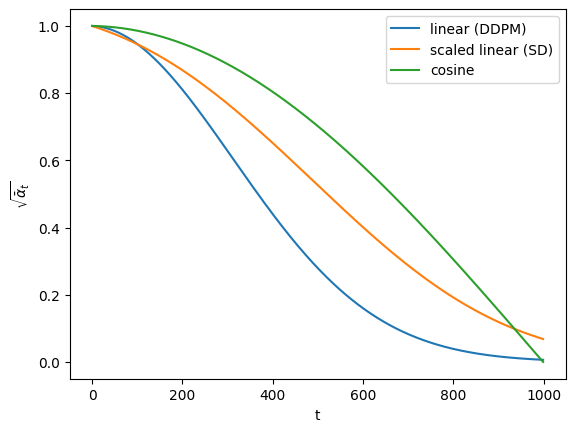

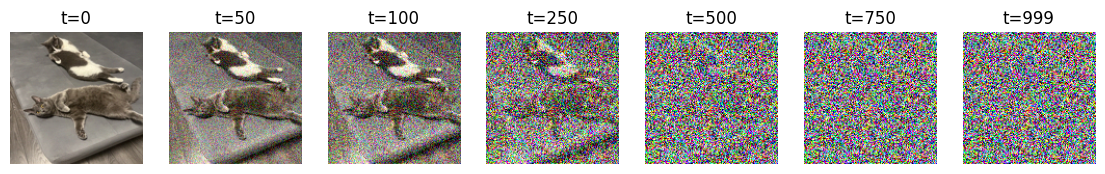

In [3]:
from diffusers import DDPMScheduler

# Сколько сигнала остаётся к шагу t при разных schedule
for name, kw in {
    "linear (DDPM)": dict(beta_schedule="linear", beta_start=1e-4, beta_end=0.02),
    "scaled linear (SD)": dict(beta_schedule="scaled_linear", beta_start=0.00085, beta_end=0.012),
    "cosine": dict(beta_schedule="squaredcos_cap_v2"),
}.items():
    s = DDPMScheduler(num_train_timesteps=1000, **kw)
    plt.plot(s.alphas_cumprod.sqrt(), label=name)
plt.xlabel("t"); plt.ylabel(r"$\sqrt{\bar\alpha_t}$"); plt.legend(); plt.show()

# Зашумляем одну картинку по формуле q(x_t | x_0) = N(√ᾱ_t x_0, (1-ᾱ_t) I)
x0 = load_image("assets/cats.jpg", size=128)
scheduler = DDPMScheduler(num_train_timesteps=1000)
ts = torch.tensor([0, 50, 100, 250, 500, 750, 999])
noise = torch.randn_like(x0)
xt = scheduler.add_noise(x0.repeat(len(ts), 1, 1, 1), noise.repeat(len(ts), 1, 1, 1), ts)
show_grid(xt, titles=[f"t={t}" for t in ts.tolist()])

## 3. Reverse process и что мы учим

Мы хотим сэмплировать из $\mathbf{x}_T \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$, т.е. нужно $q(\mathbf{x}_{t-1} \vert \mathbf{x}_t)$

Оценивание $q(\mathbf{x}_{t-1} \vert \mathbf{x}_t)$ -- сложная задача, которую мы будем решать с помощью модели $p_\theta$, которая будет аппроксимировать данное распределение.

$p_\theta$ – моделирует нормальное распределение, тк $q(\mathbf{x}_{t-1} \vert \mathbf{x}_t)$ – нормальное распределение (при малых $\beta_t$) — когда шаг шума маленький, обратный шаг тоже почти не меняет картинку и хорошо приближается гауссианой.

$$p_\theta(\mathbf{x}_{0:T}) = p(\mathbf{x}_T) \prod^T_{t=1} p_\theta(\mathbf{x}_{t-1} \vert \mathbf{x}_t) \quad
p_\theta(\mathbf{x}_{t-1} \vert \mathbf{x}_t) = \mathcal{N}(\mathbf{x}_{t-1}; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t), \boldsymbol{\Sigma}_\theta(\mathbf{x}_t, t))$$

### От среднего и дисперсии к предсказанию шума

Сеть могла бы выдавать среднее и дисперсию обратного шага. В DDPM она предсказывает шум $\epsilon$ из forward process. Шесть шагов, почему так.

**1. Обратный шаг напрямую не посчитать.** По Байесу $q(x_{t-1}\mid x_t) \propto q(x_t\mid x_{t-1})\,q(x_{t-1})$, а $q(x_{t-1}) = \int q(x_{t-1}\mid x_0)\,q(x_0)\,dx_0$ требует распределения данных $q(x_0)$, которого у нас нет — только выборка.

**2. При известном $x_0$ — можно.** Все три сомножителя формулы Байеса — $q(x_t\mid x_{t-1})$, $q(x_{t-1}\mid x_0)$, $q(x_t\mid x_0)$ — гауссианы forward process, и

$$
q(x_{t-1}\mid x_t, x_0) = \mathcal N\big(\tilde\mu_t(x_t, x_0),\ \tilde\beta_t I\big), \qquad \tilde\mu_t = \tfrac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,x_t + \tfrac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,x_0, \qquad \tilde\beta_t = \tfrac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t
$$

<details>
<summary><b>Вывод к шагу 2: $q(x_{t-1}\mid x_t, x_0)$, $\tilde\mu_t$ и $\tilde\beta_t$ (выделение полного квадрата)</b></summary>

По марковости $q(x_t\mid x_{t-1}, x_0) = q(x_t\mid x_{t-1})$. Перемножаем три гауссианы и смотрим на показатель экспоненты как на квадратный трёхчлен по $x_{t-1}$: коэффициент при $x_{t-1}^2$ даёт $1/\tilde\beta_t$, коэффициент при $x_{t-1}$ — $2\tilde\mu_t/\tilde\beta_t$.

$$\begin{aligned}
q(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0) 
&= q(\mathbf{x}_t \vert \mathbf{x}_{t-1}, \mathbf{x}_0) \frac{ q(\mathbf{x}_{t-1} \vert \mathbf{x}_0) }{ q(\mathbf{x}_t \vert \mathbf{x}_0) } \\
&\propto \exp \Big(-\frac{1}{2} \big(\frac{(\mathbf{x}_t - \sqrt{\alpha_t} \mathbf{x}_{t-1})^2}{\beta_t} + \frac{(\mathbf{x}_{t-1} - \sqrt{\bar{\alpha}_{t-1}} \mathbf{x}_0)^2}{1-\bar{\alpha}_{t-1}} - \frac{(\mathbf{x}_t - \sqrt{\bar{\alpha}_t} \mathbf{x}_0)^2}{1-\bar{\alpha}_t} \big) \Big) \\
&= \exp \Big(-\frac{1}{2} \big(\frac{\mathbf{x}_t^2 - 2\sqrt{\alpha_t} \mathbf{x}_t \color{blue}{\mathbf{x}_{t-1}} \color{black}{+ \alpha_t} \color{red}{\mathbf{x}_{t-1}^2} }{\beta_t} + \frac{ \color{red}{\mathbf{x}_{t-1}^2} \color{black}{- 2 \sqrt{\bar{\alpha}_{t-1}} \mathbf{x}_0} \color{blue}{\mathbf{x}_{t-1}} \color{black}{+ \bar{\alpha}_{t-1} \mathbf{x}_0^2}  }{1-\bar{\alpha}_{t-1}} - \frac{(\mathbf{x}_t - \sqrt{\bar{\alpha}_t} \mathbf{x}_0)^2}{1-\bar{\alpha}_t} \big) \Big) \\
&= \exp\Big( -\frac{1}{2} \big( \color{red}{(\frac{\alpha_t}{\beta_t} + \frac{1}{1 - \bar{\alpha}_{t-1}})} \mathbf{x}_{t-1}^2 - \color{blue}{(\frac{2\sqrt{\alpha_t}}{\beta_t} \mathbf{x}_t + \frac{2\sqrt{\bar{\alpha}_{t-1}}}{1 - \bar{\alpha}_{t-1}} \mathbf{x}_0)} \mathbf{x}_{t-1} \color{black}{ + C(\mathbf{x}_t, \mathbf{x}_0) \big) \Big)}
\end{aligned}$$

$C(\mathbf{x}_t, \mathbf{x}_0)$ не зависит от $\mathbf{x}_{t-1}$

$$\begin{aligned}
\tilde{\beta}_t 
&= 1/(\frac{\alpha_t}{\beta_t} + \frac{1}{1 - \bar{\alpha}_{t-1}}) 
= 1/(\frac{\alpha_t - \bar{\alpha}_t + \beta_t}{\beta_t(1 - \bar{\alpha}_{t-1})})
= \color{green}{\frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t} \cdot \beta_t} \\
\tilde{\boldsymbol{\mu}}_t (\mathbf{x}_t, \mathbf{x}_0)
&= (\frac{\sqrt{\alpha_t}}{\beta_t} \mathbf{x}_t + \frac{\sqrt{\bar{\alpha}_{t-1} }}{1 - \bar{\alpha}_{t-1}} \mathbf{x}_0)/(\frac{\alpha_t}{\beta_t} + \frac{1}{1 - \bar{\alpha}_{t-1}}) \\
&= (\frac{\sqrt{\alpha_t}}{\beta_t} \mathbf{x}_t + \frac{\sqrt{\bar{\alpha}_{t-1} }}{1 - \bar{\alpha}_{t-1}} \mathbf{x}_0) \color{green}{\frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t} \cdot \beta_t} \\
&= \frac{\sqrt{\alpha_t}(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} \mathbf{x}_t + \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1 - \bar{\alpha}_t} \mathbf{x}_0\\
\end{aligned}$$

</details>

На обучении $x_0$ есть, на инференсе — нет. Сеть $p_\theta(x_{t-1}\mid x_t) = \mathcal N(\mu_\theta, \Sigma_\theta)$ учится приближать это распределение, не видя $x_0$.

**3. Loss — ELBO, как в VAE (лекция 8).** Распадается на KL по timestep'ам:

$$
L = \underbrace{L_T}_{\text{константа}} + \sum_{t=2}^{T}\underbrace{\text{KL}\big(q(x_{t-1}\mid x_t,x_0)\,\|\,p_\theta(x_{t-1}\mid x_t)\big)}_{L_{t-1}} + \underbrace{L_0}_{\text{последний шаг}}
$$

$L_T$ не зависит от $\theta$ — выбрасываем; $L_0$ на практике учат так же, как остальные шаги.

<details>
<summary><b>Вывод к шагу 3: ELBO и разложение на $L_T, L_t, L_0$ (в выводе слагаемое $L_{t-1}$ после переиндексации обозначено $L_t$)</b></summary>

**Много математики**

Ниже будет приведено довольно много формул. Знать их наизусть, не принесет большой пользы, но полезно понять, откуда берется финальный результат (в итоге все сводится к тому, что надо знать формулы школьной математики + иметь представление о том, что такое KL дивергенция)

---

[details here](https://arxiv.org/abs/1503.03585)

Далее, лосс функция, что мы хотим считать. Выражать мы ее будем через [ELBO](https://en.wikipedia.org/wiki/Evidence_lower_bound)

$$\begin{aligned}
- \log p_\theta(\mathbf{x}_0) 
&\leq - \log p_\theta(\mathbf{x}_0) + D_\text{KL}(q(\mathbf{x}_{1:T}\vert\mathbf{x}_0) \| p_\theta(\mathbf{x}_{1:T}\vert\mathbf{x}_0) ) & \small{\text{; KL is non-negative}}\\
&= - \log p_\theta(\mathbf{x}_0) + \mathbb{E}_{\mathbf{x}_{1:T}\sim q(\mathbf{x}_{1:T} \vert \mathbf{x}_0)} \Big[ \log\frac{q(\mathbf{x}_{1:T}\vert\mathbf{x}_0)}{p_\theta(\mathbf{x}_{0:T}) / p_\theta(\mathbf{x}_0)} \Big] \\
&= - \log p_\theta(\mathbf{x}_0) + \mathbb{E}_q \Big[ \log\frac{q(\mathbf{x}_{1:T}\vert\mathbf{x}_0)}{p_\theta(\mathbf{x}_{0:T})} + \log p_\theta(\mathbf{x}_0) \Big] \\
&= \mathbb{E}_q \Big[ \log \frac{q(\mathbf{x}_{1:T}\vert\mathbf{x}_0)}{p_\theta(\mathbf{x}_{0:T})} \Big] \\
\text{Let }L_\text{VLB} 
&= \mathbb{E}_{q(\mathbf{x}_{0:T})} \Big[ \log \frac{q(\mathbf{x}_{1:T}\vert\mathbf{x}_0)}{p_\theta(\mathbf{x}_{0:T})} \Big] \geq - \mathbb{E}_{q(\mathbf{x}_0)} \log p_\theta(\mathbf{x}_0)
\end{aligned}
$$


$$
\begin{aligned}
L_\text{VLB} 
&= \mathbb{E}_{q(\mathbf{x}_{0:T})} \Big[ \log\frac{q(\mathbf{x}_{1:T}\vert\mathbf{x}_0)}{p_\theta(\mathbf{x}_{0:T})} \Big] \\
&= \mathbb{E}_q \Big[ \log\frac{\prod_{t=1}^T q(\mathbf{x}_t\vert\mathbf{x}_{t-1})}{ p_\theta(\mathbf{x}_T) \prod_{t=1}^T p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t) } \Big] \\
&= \mathbb{E}_q \Big[ -\log p_\theta(\mathbf{x}_T) + \sum_{t=1}^T \log \frac{q(\mathbf{x}_t\vert\mathbf{x}_{t-1})}{p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t)} \Big] \\
&= \mathbb{E}_q \Big[ -\log p_\theta(\mathbf{x}_T) + \sum_{t=2}^T \log \frac{q(\mathbf{x}_t\vert\mathbf{x}_{t-1})}{p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t)} + \log\frac{q(\mathbf{x}_1 \vert \mathbf{x}_0)}{p_\theta(\mathbf{x}_0 \vert \mathbf{x}_1)} \Big] \\
&= \mathbb{E}_q \Big[ -\log p_\theta(\mathbf{x}_T) + \sum_{t=2}^T \log \Big( \frac{q(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0)}{p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t)}\cdot \frac{q(\mathbf{x}_t \vert \mathbf{x}_0)}{q(\mathbf{x}_{t-1}\vert\mathbf{x}_0)} \Big) + \log \frac{q(\mathbf{x}_1 \vert \mathbf{x}_0)}{p_\theta(\mathbf{x}_0 \vert \mathbf{x}_1)} \Big] \\
&= \mathbb{E}_q \Big[ -\log p_\theta(\mathbf{x}_T) + \sum_{t=2}^T \log \frac{q(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0)}{p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t)} + \sum_{t=2}^T \log \frac{q(\mathbf{x}_t \vert \mathbf{x}_0)}{q(\mathbf{x}_{t-1} \vert \mathbf{x}_0)} + \log\frac{q(\mathbf{x}_1 \vert \mathbf{x}_0)}{p_\theta(\mathbf{x}_0 \vert \mathbf{x}_1)} \Big] \\
&= \mathbb{E}_q \Big[ -\log p_\theta(\mathbf{x}_T) + \sum_{t=2}^T \log \frac{q(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0)}{p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t)} + \log\frac{q(\mathbf{x}_T \vert \mathbf{x}_0)}{q(\mathbf{x}_1 \vert \mathbf{x}_0)} + \log \frac{q(\mathbf{x}_1 \vert \mathbf{x}_0)}{p_\theta(\mathbf{x}_0 \vert \mathbf{x}_1)} \Big]\\
&= \mathbb{E}_q \Big[ \log\frac{q(\mathbf{x}_T \vert \mathbf{x}_0)}{p_\theta(\mathbf{x}_T)} + \sum_{t=2}^T \log \frac{q(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0)}{p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t)} - \log p_\theta(\mathbf{x}_0 \vert \mathbf{x}_1) \Big] \\
&= \mathbb{E}_q [\underbrace{D_\text{KL}(q(\mathbf{x}_T \vert \mathbf{x}_0) \parallel p_\theta(\mathbf{x}_T))}_{L_T} + \sum_{t=2}^T \underbrace{D_\text{KL}(q(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0) \parallel p_\theta(\mathbf{x}_{t-1} \vert\mathbf{x}_t))}_{L_{t-1}} \underbrace{- \log p_\theta(\mathbf{x}_0 \vert \mathbf{x}_1)}_{L_0} ]
\end{aligned}
$$

$$
\begin{aligned}
L_\text{VLB} &= L_T + L_{T-1} + \dots + L_0 \\
\text{where } L_T &= D_\text{KL}(q(\mathbf{x}_T \vert \mathbf{x}_0) \parallel p_\theta(\mathbf{x}_T)) \\
L_t &= D_\text{KL}(q(\mathbf{x}_t \vert \mathbf{x}_{t+1}, \mathbf{x}_0) \parallel p_\theta(\mathbf{x}_t \vert\mathbf{x}_{t+1})) \text{ for }1 \leq t \leq T-1 \\
L_0 &= - \log p_\theta(\mathbf{x}_0 \vert \mathbf{x}_1)
\end{aligned}
$$


- $L_T$: не зависит от модели
- $L_t$: [KL дивергенция двух гауссовских распределений может быть посчитана аналитически](https://en.wikipedia.org/wiki/Kullback%E2%80%93Leibler_divergence#Multivariate_normal_distributions)
- $L_0$: в [DDPM](https://arxiv.org/pdf/2006.11239) последний шаг моделируется дискретизованным гауссовым декодером (отдельный член loss, а не отдельная сеть). В последующих статьях показали, что проще (и эффективнее) просто на это забить

</details>

**4. Дисперсию не учим.** $\Sigma_\theta = \sigma_t^2 I$, $\sigma_t^2 = \beta_t$ или $\tilde\beta_t$ (по умолчанию). Тогда KL гауссиан — расстояние между средними:

$$
L_{t-1} = \tfrac{1}{2\sigma_t^2}\,\|\tilde\mu_t(x_t,x_0) - \mu_\theta(x_t,t)\|^2
$$

Дисперсия нужна только на инференсе: $x_{t-1} = \mu_\theta + \sigma_t z$, где $z \sim \mathcal N(0,I)$ — случайная добавка шага (не путать с $\epsilon$ — шумом forward process).

**5. От среднего к шуму.** В $\tilde\mu_t$ подставим $x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\epsilon)/\sqrt{\bar\alpha_t}$:

$$
\tilde\mu_t = \tfrac{1}{\sqrt{\alpha_t}}\Big(x_t - \tfrac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon\Big)
$$

(здесь $\beta_t = 1-\alpha_t$; в выводе ниже записано через $1-\alpha_t$)

Осталось только $x_t$ (сеть его видит) и $\epsilon$. Значит, предсказываем $\epsilon_\theta(x_t,t)$, а $\mu_\theta$ собираем по этой формуле:

$$
L_{t-1} = \underbrace{\tfrac{\beta_t^2}{2\sigma_t^2\,\alpha_t(1-\bar\alpha_t)}}_{\text{coef}_t}\,\|\epsilon - \epsilon_\theta(x_t,t)\|^2
$$

<details>
<summary><b>Вывод к шагу 5: параметризация $L_t$ через $\epsilon_\theta$</b></summary>

Подставляем $x_0$ через шум:

$$\mathbf{x}_0 = \frac{1}{\sqrt{\bar{\alpha}_t}}(\mathbf{x}_t - \sqrt{1 - \bar{\alpha}_t}\boldsymbol{\epsilon}_t)$$

$$\begin{aligned}
\tilde{\boldsymbol{\mu}}_t
&= \frac{\sqrt{\alpha_t}(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} \mathbf{x}_t + \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1 - \bar{\alpha}_t} \frac{1}{\sqrt{\bar{\alpha}_t}}(\mathbf{x}_t - \sqrt{1 - \bar{\alpha}_t}\boldsymbol{\epsilon}_t) \\
&= \color{cyan}{\frac{1}{\sqrt{\alpha_t}} \Big( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \boldsymbol{\epsilon}_t \Big)}
\end{aligned}$$

**Параметризация $L_t$ для обучения**

1. Необходимо моделировать $p_\theta(\mathbf{x}_{t-1} \vert \mathbf{x}_t) = \mathcal{N}(\mathbf{x}_{t-1}; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t), \boldsymbol{\Sigma}_\theta(\mathbf{x}_t, t))$
2. Выше мы показали, что среднее должно быть $\tilde{\boldsymbol{\mu}}_t = \frac{1}{\sqrt{\alpha_t}} \Big( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \boldsymbol{\epsilon}_t \Big)$, $x_t$ -- доступно как вход

Складывая два факта, получаем

$$\begin{aligned}
\boldsymbol{\mu}_\theta(\mathbf{x}_t, t) &= \frac{1}{\sqrt{\alpha_t}} \Big( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t) \Big) \\
\text{Thus }\mathbf{x}_{t-1} &= \mathcal{N}(\mathbf{x}_{t-1}; \frac{1}{\sqrt{\alpha_t}} \Big( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t) \Big), \boldsymbol{\Sigma}_\theta(\mathbf{x}_t, t))
\end{aligned}$$


---

$$
\begin{aligned}
L_t 
&= \mathbb{E}_{\mathbf{x}_0, \boldsymbol{\epsilon}} \Big[\frac{1}{2 \sigma_t^2} \| \tilde{\boldsymbol{\mu}}_t(\mathbf{x}_t, \mathbf{x}_0) - \boldsymbol{\mu}_\theta(\mathbf{x}_t, t) \|^2 \Big] \\
&= \mathbb{E}_{\mathbf{x}_0, \boldsymbol{\epsilon}} \Big[\frac{1}{2  \sigma_t^2} \| \frac{1}{\sqrt{\alpha_t}} \Big( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \boldsymbol{\epsilon}_t \Big) - \frac{1}{\sqrt{\alpha_t}} \Big( \mathbf{x}_t - \frac{1 - \alpha_t}{\sqrt{1 - \bar{\alpha}_t}} \boldsymbol{\boldsymbol{\epsilon}}_\theta(\mathbf{x}_t, t) \Big) \|^2 \Big] \\
&= \mathbb{E}_{\mathbf{x}_0, \boldsymbol{\epsilon}} \Big[\frac{ (1 - \alpha_t)^2 }{2 \alpha_t (1 - \bar{\alpha}_t) \sigma_t^2} \|\boldsymbol{\epsilon}_t - \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)\|^2 \Big] \\
&= \mathbb{E}_{\mathbf{x}_0, \boldsymbol{\epsilon}} \Big[\frac{ (1 - \alpha_t)^2 }{2 \alpha_t (1 - \bar{\alpha}_t) \sigma_t^2} \|\boldsymbol{\epsilon}_t - \boldsymbol{\epsilon}_\theta(\sqrt{\bar{\alpha}_t}\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t}\boldsymbol{\epsilon}_t, t)\|^2 \Big] 
\end{aligned}
$$

</details>

**6. Коэффициент выкидываем** — так лучше работает ([DDPM](https://arxiv.org/abs/2006.11239)):

$$
L_\text{simple} = \mathbb E_{t,\,x_0,\,\epsilon}\;\|\epsilon - \epsilon_\theta(\sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\ t)\|^2
$$

**Итог.** Обучение: картинка, случайный $t$, случайный $\epsilon$, зашумить одной формулой, MSE по шуму. Сэмплирование: $T$ раз $x_{t-1} = \mu_\theta(x_t,t) + \sigma_t z$.

<img src="./assets/ddpm-training.png" alt="diffusion-model-scheme" width="1024">

Improved DDPM ([arXiv 2102.09672](https://arxiv.org/abs/2102.09672)) учит дисперсию как интерполяцию между $\beta_t$ и $\tilde\beta_t$ ($L_\text{simple} + 0.001\,L_\text{vlb}$); не прижилось.

In [ ]:
# Шаг обучения DDPM — вся суть в пяти строках
def train_step(model, scheduler, x0):
    noise = torch.randn_like(x0)                                                      # ε
    t = torch.randint(0, scheduler.config.num_train_timesteps, (x0.shape[0],), device=x0.device)
    xt = scheduler.add_noise(x0, noise, t)                                            # √ᾱ_t x_0 + √(1-ᾱ_t) ε — одной формулой
    noise_pred = model(xt, t).sample                                                  # ε_θ(x_t, t)
    return F.mse_loss(noise_pred, noise)                                              # L_simple

## 4. Сэмплирование: от DDPM к DDIM

**DDPM:** $x_{t-1} = \mu_\theta(x_t,t) + \sigma_t z$. Шаг выведен для соседних $t, t-1$ → 1000 шагов. Случайная добавка $z$ на каждом шаге → один $x_T$ даёт разные картинки.

**DDIM** ([Song, Meng, Ermon, 2020](https://arxiv.org/abs/2010.02502)): делаем шаг не от $x_t$, а от оценки чистой картинки.

Ниже $\sigma$ — параметр DDIM, который задаёт долю случайного шума в шаге; при $\sigma^2 = \tilde\beta_t$ он совпадает с $\sigma_t$ из DDPM.

1. Из $x_t$ и предсказанного шума оцениваем $x_0$ (формула forward process, решённая относительно $x_0$):
$$\hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}$$
2. Зашумляем $\hat x_0$ до уровня $s < t$ той же формулой forward process, подставив вместо шума предсказанный $\epsilon_\theta$ и долю случайного $\sigma$:
$$x_s = \sqrt{\bar\alpha_s}\,\hat x_0 + \sqrt{1-\bar\alpha_s-\sigma^2}\;\epsilon_\theta(x_t,t) + \sigma z$$

Было $t$, стало $s < t$: шума меньше. Повторяем с $x_s$: оценка $\hat x_0$ с каждым шагом точнее, на $s = 0$ ответ — последняя $\hat x_0$.

Процесс немарковский: шаг зависит от $x_0$, не только от $x_t$. Но маргиналы $q(x_t\mid x_0)$ те же, что в DDPM, поэтому сеть $\epsilon_\theta$ не переобучаем.

<details>
<summary><b>Вывод DDIM</b></summary>

Давайте распишем $q_\sigma(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0)$ как распределение параметризованное стандартным отклонением $\sigma_t$:

$$
\begin{aligned}
\mathbf{x}_{t-1} 
&= \sqrt{\bar{\alpha}_{t-1}}\mathbf{x}_0 +  \sqrt{1 - \bar{\alpha}_{t-1}}\boldsymbol{\epsilon}_{t-1} & \\
&= \sqrt{\bar{\alpha}_{t-1}}\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_{t-1} - \sigma_t^2} \boldsymbol{\epsilon}_t + \sigma_t\boldsymbol{\epsilon} & \\
&= \sqrt{\bar{\alpha}_{t-1}} \Big( \frac{\mathbf{x}_t - \sqrt{1 - \bar{\alpha}_t} \epsilon^{(t)}_\theta(\mathbf{x}_t)}{\sqrt{\bar{\alpha}_t}} \Big) + \sqrt{1 - \bar{\alpha}_{t-1} - \sigma_t^2} \epsilon^{(t)}_\theta(\mathbf{x}_t) + \sigma_t\boldsymbol{\epsilon} \\
q_\sigma(\mathbf{x}_{t-1} \vert \mathbf{x}_t, \mathbf{x}_0)
&= \mathcal{N}(\mathbf{x}_{t-1}; \sqrt{\bar{\alpha}_{t-1}} \Big( \frac{\mathbf{x}_t - \sqrt{1 - \bar{\alpha}_t} \epsilon^{(t)}_\theta(\mathbf{x}_t)}{\sqrt{\bar{\alpha}_t}} \Big) + \sqrt{1 - \bar{\alpha}_{t-1} - \sigma_t^2} \epsilon^{(t)}_\theta(\mathbf{x}_t), \sigma_t^2 \mathbf{I})
\end{aligned}
$$

Таким образом, мы можем изменять гиперпараметр $\sigma_t$ для контроля стохастичности. 

Особенный случай: $\sigma_t = 0$ и процесс становится **детерминированным**. Такого типа модель называется [denoising diffusion implicit model](https://arxiv.org/abs/2010.02502)

Во timestep генерации, мы также можем воспользоваться strided sampling:

$$q_{\sigma, s < t}(\mathbf{x}_s \vert \mathbf{x}_t, \mathbf{x}_0)
= \mathcal{N}(\mathbf{x}_s; \sqrt{\bar{\alpha}_s} \Big( \frac{\mathbf{x}_t - \sqrt{1 - \bar{\alpha}_t} \epsilon^{(t)}_\theta(\mathbf{x}_t)}{\sqrt{\bar{\alpha}_t}} \Big) + \sqrt{1 - \bar{\alpha}_s - \sigma_t^2} \epsilon^{(t)}_\theta(\mathbf{x}_t), \sigma_t^2 \mathbf{I})$$

</details>

**$\sigma$ — ручка стохастичности.** $\sigma_t^2 = \tilde\beta_t$, $s = t-1$ → в точности DDPM. $\sigma = 0$ → **детерминированный** процесс: картинка — функция от $x_T$. Это DDIM.

**Пропуск шагов.** Формула содержит только $\hat x_0$ и $\epsilon_\theta$, оба из текущего $x_t$, поэтому $s$ — любой. 50 или 20 точек вместо 1000.

**Результат.** CIFAR-10, $\sigma=0$: FID 4.16 за 100 шагов против 4.04 за 1000 (оба DDIM); DDPM при 100 шагах заметно хуже. Один $x_T$ → одна сцена при любом числе шагов. Интерполяция между $x_T$ даёт плавный переход картинок. При $\sigma = 0$ последовательность шагов — численное решение обыкновенного дифференциального уравнения (ODE): траектория шум → картинка гладкая, но кривая (подробнее — в итогах).

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


config.json:   0%|          | 0.00/699 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/143M [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

DDPM 1000: 155.5 s
DDIM 50: 8.4 s
DDIM 20: 3.0 s


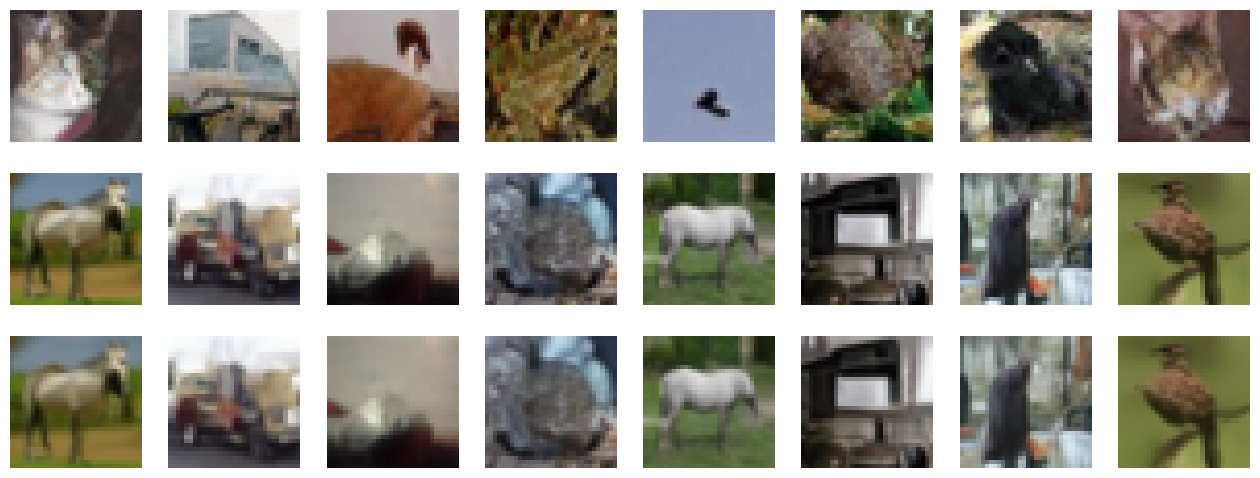

In [6]:
from diffusers import UNet2DModel, DDPMScheduler, DDIMScheduler

model_id = "google/ddpm-cifar10-32"                       # маленькая pixel-space DDPM, ~140 МБ
model = UNet2DModel.from_pretrained(model_id).to(device).eval()

@torch.no_grad()
def sample(scheduler, x_T, num_steps, eta=0.0):
    scheduler.set_timesteps(num_steps)
    x = x_T.clone()
    for t in scheduler.timesteps:
        eps = model(x, t).sample                                            # ε_θ(x_t, t)
        kw = {"eta": eta} if isinstance(scheduler, DDIMScheduler) else {}
        x = scheduler.step(eps, t, x, **kw).prev_sample
    return x

x_T = torch.randn(8, 3, 32, 32, device=device)                              # один и тот же старт для всех сэмплеров
results = {}
for name, sch, n in [("DDPM 1000", DDPMScheduler.from_pretrained(model_id), 1000),
                     ("DDIM 50",   DDIMScheduler.from_pretrained(model_id), 50),
                     ("DDIM 20",   DDIMScheduler.from_pretrained(model_id), 20)]:
    start = time.time()
    results[name] = sample(sch, x_T, n)
    print(f"{name}: {time.time() - start:.1f} s")
show_rows(results)   # DDIM 50 и DDIM 20 дают одни и те же сцены; DDPM с тем же x_T — другие

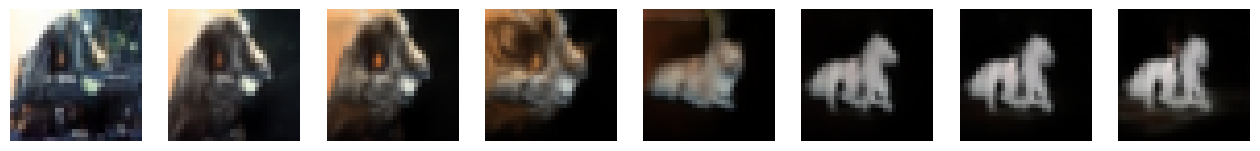

In [7]:
# Интерполяция в x_T при детерминированном DDIM: плавный переход между двумя картинками
a, b = torch.randn(2, 3, 32, 32, device=device)
alphas = torch.linspace(0, 1, 8, device=device)
x_T = torch.stack([slerp(al, a, b) for al in alphas])
show_grid(sample(DDIMScheduler.from_pretrained(model_id), x_T, 50))

## 5. Параметризации: что именно предсказывает сеть

Формулу $\hat x_0$ через $\epsilon$ мы уже использовали в DDIM. Сеть можно учить предсказывать любую из трёх величин:

Понадобится одно обозначение. $\mathrm{SNR}_t = \bar\alpha_t / (1-\bar\alpha_t)$ — отношение сигнал/шум в $x_t$: дисперсия слагаемого с $x_0$ к дисперсии слагаемого с $\epsilon$. При $t \to 0$ оно огромное (почти чистая картинка), при $t \to T$ стремится к нулю (почти чистый шум).

| Что предсказывает сеть | Как получить $\hat x_0$ | Где плохо |
|---|---|---|
| $\epsilon$-prediction (DDPM) | $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$ | при $\bar\alpha_t\to 0$ — деление на малое число |
| $x_0$-prediction | сеть сразу выдаёт $\hat x_0$ | при малом шуме: крошечная ошибка в $\hat x_0$ даёт большую ошибку в неявном $\hat\epsilon$ |
| $v$-prediction ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)): $v=\sqrt{\bar\alpha_t}\,\epsilon-\sqrt{1-\bar\alpha_t}\,x_0$ | $\hat x_0=\sqrt{\bar\alpha_t}\,x_t-\sqrt{1-\bar\alpha_t}\,\hat v$ | устойчив на обоих концах; использовался в SD 2 (768) — по карточке модели |

- Все три — линейные комбинации $x_0$ и $\epsilon$, переход между ними детерминирован
- Выбор параметризации — это выбор весов timestep'ов в loss. Все три цели связаны линейно, и их ошибки отличаются на множитель из SNR: $\|\epsilon-\hat\epsilon\|^2=\mathrm{SNR}_t\,\|x_0-\hat x_0\|^2$, $\|v-\hat v\|^2=(1+\mathrm{SNR}_t)\,\|x_0-\hat x_0\|^2$. MSE по шуму — это MSE по картинке с весом $\mathrm{SNR}_t$: сильный штраф при малом шуме, почти нулевой при большом. $v$-prediction даёт вес $1+\mathrm{SNR}_t$, который нигде не обнуляется.

$v$-prediction — ближайший родственник «скорости» во flow matching (лекция 10).

## 6. Архитектура: как устроена $\epsilon_\theta(x_t, t)$

**Требования к сети**

- Вход и выход одного размера: картинка $x_t$ → шум той же формы
- Нужен и локальный контекст (текстуры), и глобальный (композиция)
- Нужен способ сообщить сети текущий шаг $t$

### DDPM (2020): U-Net + timestep через сложение

- U-Net: encoder–decoder со skip connections (знаком по лекции 6 про сегментацию)
- Backbone — Wide ResNet; нормализация GroupNorm (по группам каналов внутри одного примера, не зависит от batch size)
- Self-attention на разрешении 16×16
- timestep $t$: sinusoidal positional embedding (как позиции в трансформере) → **прибавляется к активациям в каждом residual-блоке**
- Так одна сеть обслуживает все $T$ шагов

### ADM: «Diffusion Models Beat GANs» ([Dhariwal & Nichol, 2021](https://arxiv.org/abs/2105.05233))

- Архитектура взята из **BigGAN**: residual-блоки BigGAN для up/downsampling
- Больше attention-голов, attention на разрешениях 32, 16, 8
- Главное — **Adaptive Group Normalization**:

$$\text{AdaGN}(h, y) = y_s \cdot \text{GroupNorm}(h) + y_b$$

- $[y_s, y_b]$ — линейная проекция эмбеддинга времени (и класса)
- timestep не прибавляется, а **модулирует нормализацию**: масштабирует и сдвигает признаки в каждом блоке
- В статье: FID 13.06 с AdaGN против 15.08 с простым сложением
- Это тот же приём, что AdaIN в StyleGAN (урок 8) и AdaLN в DiT/VAR (часть 1) — одна идея под разными именами

### DiT ([Peebles & Xie, 2023](https://arxiv.org/abs/2212.09748))

- U-Net → трансформер на патчах латента
- AdaLN — то же, что AdaGN, но с LayerNorm вместо GroupNorm (так принято в трансформерах): масштаб и сдвиг нормализации вычисляются из условия
- Условие (timestep + класс) через adaLN-Zero: AdaLN плюс гейт — обучаемый множитель на выходе блока, инициализированный нулём, так что блок стартует как тождественное отображение
- Показал, что диффузия масштабируется как трансформеры
- SD3 ([arXiv 2403.03206](https://arxiv.org/abs/2403.03206)) и FLUX — трансформеры с двумя потоками весов (картинка и текст), подробно в лекции 11

### Эволюция в одной таблице

| Модель | Backbone | Как подаётся условие |
|---|---|---|
| DDPM | U-Net | timestep — сложение с активациями |
| ADM | U-Net с BigGAN-блоками | timestep (и класс) — AdaGN |
| LDM (раздел 8) | U-Net в латенте | timestep — как раньше, + cross-attention на текст |
| DiT | трансформер на патчах | adaLN-Zero |

In [ ]:
class AdaGN(nn.Module):
    """AdaGN(h, y) = y_s · GroupNorm(h) + y_b — timestep (и класс) модулируют нормализацию"""
    def __init__(self, channels: int, emb_dim: int):
        super().__init__()
        self.norm = nn.GroupNorm(32, channels)
        self.proj = nn.Linear(emb_dim, 2 * channels)          # y = [y_s, y_b]

    def forward(self, h, emb):                                 # emb — эмбеддинг времени (+ класса)
        y_s, y_b = self.proj(emb)[:, :, None, None].chunk(2, dim=1)
        return y_s * self.norm(h) + y_b

## 7. Условная генерация: classifier guidance → CFG

**Простой способ**

- Подать класс/текст в сеть: эмбеддинг → AdaGN / cross-attention
- Работает, но модель слабо «слушается» условия: класс или текст — лишь один из входов, и ничто в loss не заставляет сеть сильно тянуть картинку в его сторону

**Score — язык, на котором это удобно объяснять**

- Score — градиент лог-плотности $\nabla_x \log p(x)$: направление, в котором данные «плотнее»
- Предсказанный шум — это score с точностью до множителя: $\epsilon_\theta(x_t, t) \approx -\sqrt{1-\bar\alpha_t}\,\nabla_{x_t}\log p(x_t)$
- По Байесу $\nabla\log p(x_t\mid y)=\nabla\log p(x_t)+\nabla\log p(y\mid x_t)$: чтобы идти к классу $y$, к обычному score добавляем градиент классификатора. Отсюда оба метода ниже

**Classifier guidance** ([ADM](https://arxiv.org/abs/2105.05233))

- Отдельный классификатор, обученный на зашумлённых картинках
- Его градиент $\nabla_{x_t}\log p(y\mid x_t)$ с масштабом $\gamma$ сдвигает среднее шага к классу
- Сдвиг среднего: $\mu' = \mu_\theta(x_t,t) + \gamma\,\Sigma\,\nabla_{x_t}\log p_\phi(y\mid x_t)$
- Минус: нужен отдельный классификатор, устойчивый к шуму

**Classifier-free guidance** ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598), [OpenReview](https://openreview.net/forum?id=qw8AKxfYbI))

- Одна сеть учится и условно, и безусловно: при обучении условие с вероятностью $p_\text{uncond}$ (0.1–0.2) заменяется на пустое
- На инференсе два forward на шаг (с условием и без), и предсказание **экстраполируется** от безусловного к условному:

$$
\begin{aligned}
\bar{\boldsymbol{\epsilon}}_\theta(\mathbf{x}_t, t, y)
&= \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t, y) + w \big(\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t, y) - \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t) \big) \\
&= (w+1) \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t, y) - w \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)
\end{aligned}$$

- Интуиция: разность $\epsilon_\theta(x_t,t,y)-\epsilon_\theta(x_t,t)$ — направление «что в шуме объясняется условием», $w$ усиливает его
- Та же запись $(1+w)\cdot\text{cond} - w\cdot\text{uncond}$ использовалась для логитов в VAR (ноутбук 9-1)

**Trade-off**

- Малый $w$ (0.1–0.3) — лучший FID, $w\ge 4$ — лучший IS
- Большой $w$ → картинки резче и точнее по промпту, но разнообразие падает
- Тот же компромисс качество/разнообразие, что precision/recall в части 1
- В diffusers для SD 1.5 по умолчанию `guidance_scale = 7.5`; там запись $\text{uncond}+s\cdot(\text{cond}-\text{uncond})$, т.е. $s=1+w$

**Цена**: ×2 вычислений на шаг → мотивация для guidance distillation (лекция 11)

In [ ]:
# CFG: два forward на шаг и экстраполяция от безусловного к условному
eps_cond   = unet(x_t, t, encoder_hidden_states=text_emb).sample      # с промптом
eps_uncond = unet(x_t, t, encoder_hidden_states=empty_emb).sample     # с пустым промптом ""
eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)           # запись diffusers: guidance_scale = 1 + w

## 8. Latent Diffusion и cross-attention с текстом

[LDM](https://arxiv.org/abs/2112.10752) предложила делать диффузию не в пикселях, а в латентном пространстве VAE; большинство крупных моделей с тех пор так и делает

Главным образом, это обосновывается тем, что *pixel space* генераторы слишком дорогие и не могут масштабироваться на большие изображения (>1 мегапикселя)

<img src="./assets/ldm.png" width=1024>


- **VAE**
  - Отвечает за переход между pixel space и latent space: энкодер сжимает картинку в латент, декодер восстанавливает картинку из латента. То есть во timestep инференса мы обычно применяем decoder часть (мы можем применять и encoder часть для *image-to-image* сценария, см. лекцию 11). Во timestep train нам нужен encoder для перевода обучающих сэмплов в latent space. В качестве VAE используется либо VQVAE, либо KL-regularized VAE (чаще второе)
  - VAE обучают *до* обучения диффузионной сети (как первый этап)
- **Conditioning**
  - Сеть, кодирующая информацию, на которую мы обуславливаемся. В классических сценариях является pretrained и не дообучается
  - Основной conditioning сценарий – текст. Пару лет назад основной моделью для этого был CLIP (например, именно он используется в первых версиях популярного семейства Stable Diffusion). Сейчас всё чаще уходят от CLIP в сторону больших текстовых моделей (T5-XXL в Imagen и SD3, LLM-энкодеры)
- **Latent diffusion model**
  - Модель проделывает весь процесс, который мы описывали выше, только не в пространстве пикселей, а в latent space, что позволяет сильно сэкономить по памяти ввиду меньшего разрешения изображения
  - Оригинально использовался *U-net*, однако современные сети перешли на трансформерную архитектуру

**Числа для SD 1.x** (по репозиторию модели)

- VAE с downsampling ×8, латент с 4 каналами: 512×512 → 64×64×4, KL-регуляризованный
- U-Net ≈860M параметров
- Текстовый энкодер CLIP ViT-L/14 → 77 токенов × 768
- Латент домножается на scaling factor 0.18215, чтобы иметь единичную дисперсию

### Как текст попадает в U-Net: cross-attention

([Rombach et al.](https://arxiv.org/abs/2112.10752), Sec. 3.3)

- В attention-блоках U-Net на нескольких разрешениях запросы берутся от картинки, ключи и значения — от текста:

$$Q = W_Q\,\varphi_i(z_t), \quad K = W_K\,\tau_\theta(y), \quad V = W_V\,\tau_\theta(y), \quad \text{Attention}=\text{softmax}\Big(\frac{QK^\top}{\sqrt d}\Big)\,V$$

где $\varphi_i(z_t)$ — признаки U-Net на слое $i$, $\tau_\theta(y)$ — выход текстового энкодера (77 токенов), $d$ — размерность ключей.

- Каждая позиция латента «спрашивает» у 77 текстовых токенов, что здесь должно быть, и забирает взвешенную смесь их значений
- Эмбеддинги текста $\tau_\theta(y)$ считаются один раз на промпт и одинаковы для всех блоков и всех шагов $t$ — обновляется только картинка
- Карты внимания $QK^\top$ показывают, какие пиксели «смотрят» на какое слово — на этом построены методы редактирования (prompt-to-prompt)
- Условие на timestep по-прежнему через AdaGN/сложение, текст — только через cross-attention

**Почему латент**

- Диффузия в пикселях на 512² слишком дорога
- VAE убирает перцептивно незаметные детали, диффузия работает с семантикой
- Сравни с VAR: там VQ-токены, здесь непрерывный KL-латент

In [ ]:
class CrossAttention(nn.Module):
    """Q — от латента картинки, K и V — от токенов текста"""
    def __init__(self, d_img: int, d_txt: int, d: int):
        super().__init__()
        self.q, self.k, self.v = nn.Linear(d_img, d), nn.Linear(d_txt, d), nn.Linear(d_txt, d)

    def forward(self, z, txt):                      # z: (B, H·W, d_img) — латент, txt: (B, 77, d_txt) — текст
        Q, K, V = self.q(z), self.k(txt), self.v(txt)
        attn = (Q @ K.transpose(1, 2) / Q.shape[-1] ** 0.5).softmax(-1)   # (B, H·W, 77): веса по словам для каждой позиции
        return attn @ V                              # (B, H·W, d): выход размером с латент

## 9. Stable Diffusion: 1.x → 2 → SDXL

| Версия | Разрешение | Текстовый энкодер | U-Net | Что нового |
|---|---|---|---|---|
| SD 1.x | 512 (предобучение на 256) | CLIP ViT-L/14 | 860M | VAE с downsampling ×8; v1.5 — дообучение на laion-aesthetics v2 5+ с 10% dropout текста для CFG |
| SD 2 | 512 (base) → 768 | OpenCLIP | — | base обучена с нуля на отфильтрованном подмножестве LAION-5B; v-objective для 768-модели |
| SDXL | 1024 | два: CLIP ViT-L + OpenCLIP ViT-bigG/14 | ×3 больше | size/crop-conditioning; base + refiner — каскад из двух стадий |

### SD 1.x

<img src="./assets/sd1x.png" width=1024>

> **Stable Diffusion v1** refers to a specific configuration of the model architecture that uses a downsampling-factor 8 autoencoder with an 860M UNet and CLIP ViT-L/14 text encoder for the diffusion model. The model was pretrained on 256x256 images and then finetuned on 512x512 images.

<img src="./assets/sd1x-checkpoints.png" width=1024>

>  The **Stable-Diffusion-v1-5** checkpoint was initialized with the weights of the Stable-Diffusion-v1-2 checkpoint and subsequently fine-tuned on 595k steps at resolution 512x512 on "laion-aesthetics v2 5+" and 10% dropping of the text-conditioning to improve classifier-free guidance sampling.

### SD 2

<img src="./assets/sd2.png" width=1024>

> **Stable Diffusion v2-base**  
> The model is trained from scratch 550k steps at resolution 256x256 on a subset of LAION-5B filtered for explicit pornographic material, using the LAION-NSFW classifier with punsafe=0.1 and an aesthetic score >= 4.5. Then it is further trained for 850k steps at resolution 512x512 on the same dataset on images with resolution >= 512x512.

> **Stable Diffusion v2**
> This stable-diffusion-2 model is resumed from stable-diffusion-2-base (512-base-ema.ckpt) and trained for 150k steps using a v-objective on the same dataset. Resumed for another 140k steps on 768x768 images.

<img src="./assets/v-objective.png" width=1024>

(про v-objective подробнее — в разделе 5 и в [статье](https://arxiv.org/abs/2202.00512))

### SDXL

SDXL — двухстадийная модель: base генерирует латент, refiner дорисовывает детали в том же латентном пространстве.

<img src="./assets/sdxl2.png" width=1024>

> the UNet is 3x larger and SDXL combines a second text encoder (OpenCLIP ViT-bigG/14) with the original text encoder to significantly increase the number of parameters

> introduces size and crop-conditioning to preserve training data from being discarded and gain more control over how a generated image should be cropped

> introduces a two-stage model process; the base model (can also be run as a standalone model) generates an image as an input to the refiner model which adds additional high-quality details

<img src="./assets/sdxl.png" width=1024>

## 10. Итоги и мостик к лекции 10

- Диффузия = фиксированный forward (зашумление, марковская цепь) + обучаемый reverse: сеть предсказывает шум / $x_0$ / $v$, loss — MSE
- Сэмплирование: DDPM — 1000 стохастических шагов; DDIM — тот же $\epsilon_\theta$, детерминированная траектория за 20–50 шагов
- Архитектура — U-Net или трансформер; timestep и класс — через адаптивную нормализацию (AdaGN / AdaLN), текст — через cross-attention
- CFG — экстраполяция от безусловного предсказания к условному, ×2 вычислений на шаг
- LDM — диффузия в латенте VAE (×8 меньше по стороне): дёшево и масштабируется до мегапикселя
- **Мостик к лекции 10.** Траектория DDIM — решение ODE, но кривая: за несколько шагов её не пройти без потерь. Flow matching учит скорость вдоль **прямой** траектории шум → данные, и шагов нужно единицы